# 1. Business Understanding

FCN BU todo

In [10]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import time
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

TARGET_REALISTIC = (0.50, 0.55)
TARGET_AMBITIOUS = (0.57, 0.60)

# random seed for repeatability
RANDOM_SEED = 123
keras.utils.set_random_seed(RANDOM_SEED)

# 2. Data Understanding

Todo

In [11]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

print("Train: ", x_train.shape, "Test: ", x_test.shape)
print("Pixel range: ", x_train.min(), "-", x_train.max())
print("Class counts: ", np.bincount(y_train))

Train:  (50000, 32, 32, 3) Test:  (10000, 32, 32, 3)
Pixel range:  0 - 255
Class counts:  [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


## Example images

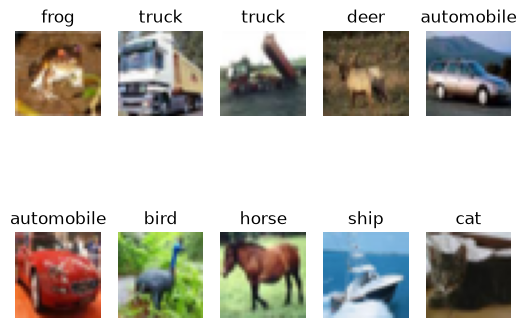

In [12]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(32, 32, 3))
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.show()

# 3. Data Preparation

todo

In [13]:
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

mean = x_train.mean(axis=(0,1,2))
std = x_train.std(axis=(0,1,2))

x_train = ((x_train - mean) / std).reshape(50000, 3072)
x_test = ((x_test - mean) / std).reshape(10000, 3072)

# 4. Modeling

todo

In [14]:
inputs = keras.Input(shape=(3072,))
x = layers.Dense(1024, activation="relu")(inputs)
x = layers.Dropout(0.3)(x)
x = layers.Dense(512, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs, name="cifar10_fcn")

In [15]:
model.summary()

Model: "cifar10_fcn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1024)           │     3,146,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,676,682 (14.03 MB)

 Trainable params: 3,676,682 (14.03 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [17]:
t0 = time.time()
history = model.fit(
    x_train, y_train,
    batch_size=64,
    epochs=20,
    validation_split=0.2,
)
print("Training time: ", round(time.time() - t0, 1), " seconds")

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.3252 - loss: 1.9719 - val_accuracy: 0.3858 - val_loss: 1.7052
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.3819 - loss: 1.7360 - val_accuracy: 0.4188 - val_loss: 1.6324
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.4066 - loss: 1.6700 - val_accuracy: 0.4289 - val_loss: 1.6176
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.4196 - loss: 1.6356 - val_accuracy: 0.4461 - val_loss: 1.5689
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.4329 - loss: 1.5981 - val_accuracy: 0.4594 - val_loss: 1.5490
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.4431 - loss: 1.5720 - val_accuracy: 0.4639 - val_loss: 1.5438
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.4509 - loss: 1.5454 - val_accuracy: 0.4652 - val_loss: 1.5199
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.4547 - loss: 1.5315 - 

# 5. Evaluation

todo

## Learning curves

todo

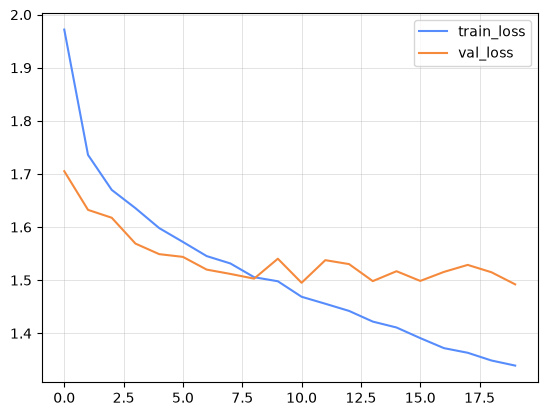

In [18]:
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.legend()
plt.grid()
plt.show()

## Test accuracy

In [19]:
test_scores = model.evaluate(x_test, y_test, verbose=2)

print("Test loss: ", test_scores[0])
print("Test accuracy: ", test_scores[1])

313/313 - 1s - 2ms/step - accuracy: 0.4977 - loss: 1.4841
Test loss:  1.4841341972351074
Test accuracy:  0.4977000057697296


## Probability distributions

todo

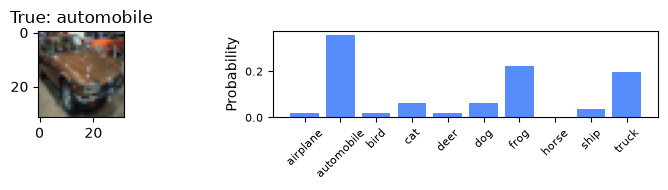

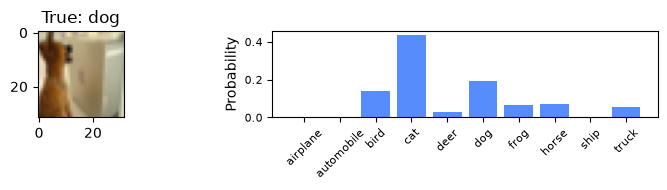

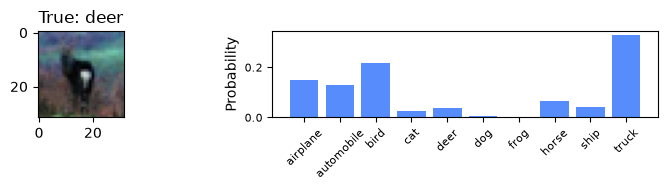

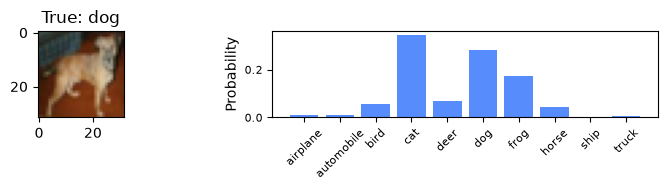

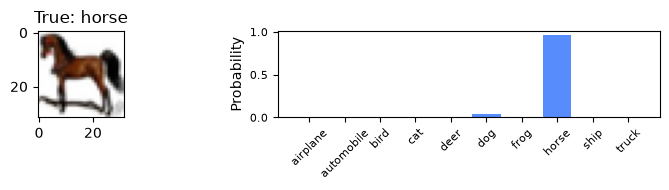

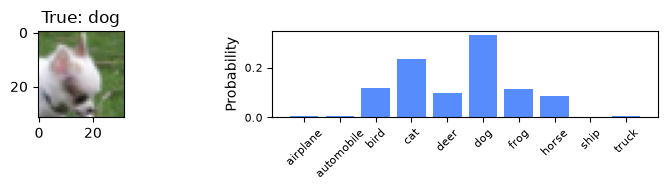

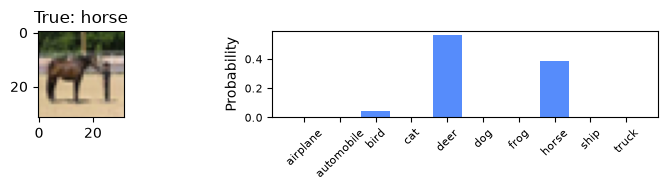

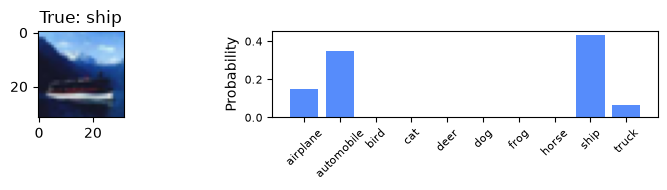

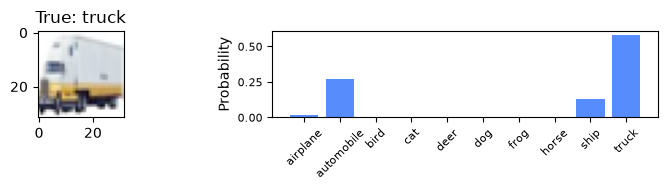

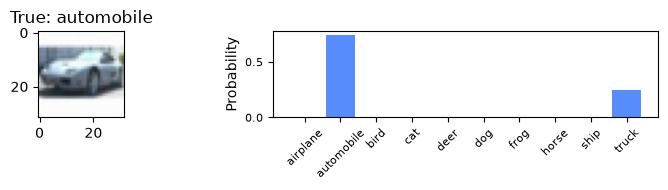

In [25]:
def to_img(x_flat):
    img = x_flat.reshape(32, 32, 3) * std + mean
    return np.clip(img / 255, 0, 1)

y = model(x_test)
start = 2000

for k in range(10):
    plt.figure(figsize=(8, 2))
    plt.subplot(1, 2, 1)
    plt.imshow(to_img(x_test[start + k]))
    plt.title("True: " + class_names[y_test[start+k]], fontsize=12)
    plt.subplot(1, 2, 2)
    plt.bar(np.arange(10), y[start+k].numpy().flatten())
    plt.xticks(range(10), class_names, rotation=45, fontsize=8)
    plt.yticks(fontsize=8)
    plt.ylabel("Probability", fontsize=10)
    plt.tight_layout()

## Misclassified images

todo

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 
Missclassified:  5023 / 10000


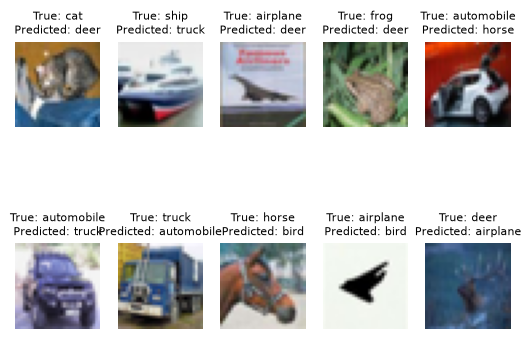

In [26]:
y_pred = np.argmax(model.predict(x_test), axis=1)
wrong = np.where(y_pred != y_test)[0]

print("Missclassified: ", len(wrong), "/", len(y_test))

for k in range(10):
    i = wrong[k]
    plt.subplot(2, 5, k+1)
    plt.imshow(to_img(x_test[i]))
    plt.title(f"True: {class_names[y_test[i]]}\nPredicted: {class_names[y_pred[i]]}", fontsize=8)
    plt.axis("off")
plt.show()